In [1]:
import COORDINATE_UTILS
import MRC_FILE as mf
from POINTS_MAIN import points as pm
import os
from MEAN_SHIFT_MERGE import mean_shift_clustering, calculate_weighted_center_of_mass
from sklearn.cluster import estimate_bandwidth
import numpy as np



# def method_1(mrc, pho_points, sugar_points, output_dir):
    
#     #First find the points from densities
#     pho_points.UNet2Points(mrc, 'PHOSPHATE_SS', True , b_bone_threshold=0.5, keyAtom_threshold=0.80)
#     sugar_points.UNet2Points(mrc,'SUGAR_SS', True, b_bone_threshold=0.5, keyAtom_threshold=0.80)
    
#     #Then Find the Clusters/Center of Mass of the clusters
#     pho_points.COM_Clustering_Simple()
#     COMS_Merged_Pho = pho_points.Merge_Coord()
    
#     sugar_points.COM_Clustering_Simple()
#     COMS_Merged_Sugar = sugar_points.Merge_Coord()
    
#     print('Number of Phosphate Points:', len(pho_points.mw_coords))
#     print('Number of Sugar Points:', len(sugar_points.mw_coords))
    
    
# def method_2(mrc, pho_points, sugar_points, output_dir):
    
#     print("Method 2: BFS Search")
#     pho_blobs = pho_points.bfs(1)
#     sugar_blobs = sugar_points.bfs(3)
    
#     print("BFS Search COM")
#     center_of_mass_phos_blob, phos_blob_dens = pho_points.center_of_mass_from_dict(pho_blobs, mrc.originial_density)
#     center_of_mass_sugar_blob, sugar_blob_dens = sugar_points.center_of_mass_from_dict(sugar_blobs, mrc.originial_density) 
#     COORDINATE_UTILS.plot_in_3D(center_of_mass_phos_blob, center_of_mass_sugar_blob,'blob_coords')
    
#     print("BFS Search COM Merged")
#     merged_phos_blobs = pho_points.merge_coord_bfs(center_of_mass_phos_blob, phos_blob_dens,.15,3)
#     merged_sugar_blobs = sugar_points.merge_coord_bfs(center_of_mass_sugar_blob, sugar_blob_dens,.15,5)
    
#     return center_of_mass_phos_blob, center_of_mass_sugar_blob, merged_phos_blobs, merged_sugar_blobs
    

def main(output_dir, NORMALIZED_MRC, PHOSPHATE_KEY_ATOMS, SECONDARY_STRUCTURE, SUGAR_KEY_ATOMS):
    
    #Create output folder if it does not exist
    output_dir = os.path.join(output_dir, 'clustering_output2')
    if not os.path.exists(output_dir):
        os.makedirs(output_dir)
    
    #Lets Read in Inputs
    mrc = mf.MRC_FILE()
    mrc.read_mrc(NORMALIZED_MRC)
    mrc.init_uNet_Structures(PHOSPHATE_KEY_ATOMS, 1)
    mrc.init_uNet_Structures(SECONDARY_STRUCTURE, 0)
    mrc.init_uNet_Structures(SUGAR_KEY_ATOMS, 2)
    
    pho_points = pm()
    sugar_points = pm()
    
    #method_1(mrc, pho_points, sugar_points, output_dir)
    
    pho_points.UNet2Points(mrc, 'PHOSPHATE_SS', True ,b_bone_threshold=0.5, keyAtom_threshold=0.80)
    sugar_points.UNet2Points(mrc, 'SUGAR_SS', True ,b_bone_threshold=0.5, keyAtom_threshold=0.80)
    
    # pho_points.COM_Clustering_Simple()
    # COMS_Merged_Pho = pho_points.Merge_Coord()
    
    # sugar_points.COM_Clustering_Simple()
    # COMS_Merged_Sugar = sugar_points.Merge_Coord()
    
    
    # print('Number of Phosphate Points:', len(pho_points.mw_coords))
    # print('Number of Sugar Points:', len(sugar_points.mw_coords))
    
    
    
    # COORDINATE_UTILS.plot_in_3D(pho_points.mw_coords, sugar_points.mw_coords,'mw_coords')
    # print("Saving mw_coords in output directory")   
    # COORDINATE_UTILS.write_as_xyz(pho_points.mw_coords, output_dir, 'phosphate_mwcoords')
    # COORDINATE_UTILS.write_as_xyz(sugar_points.mw_coords, output_dir, 'sugar_mwcoords')
    # print("=============================================")
    # print("=============================================")
    # print("=============================================")
    # print("Method 2: BFS Search")
    
    # center_of_mass_phos_blob, center_of_mass_sugar_blob, merged_phos_blobs, merged_sugar_blobs = method_2(mrc, pho_points, sugar_points, output_dir)
    
    pho_blobs = pho_points.bfs(1)
    sugar_blobs = sugar_points.bfs(3)
    
    print("BFS Search COM")
    center_of_mass_phos_blob, phos_blob_dens = pho_points.center_of_mass_from_dict(pho_blobs, mrc.originial_density)
    center_of_mass_sugar_blob, sugar_blob_dens = sugar_points.center_of_mass_from_dict(sugar_blobs, mrc.originial_density) 
    COORDINATE_UTILS.plot_in_3D(center_of_mass_phos_blob, center_of_mass_sugar_blob,'blob_coords')
    
    print("BFS Search COM Merged")
    
    

    
    merged_phos_blobs = pho_points.merge_coord_bfs(center_of_mass_phos_blob, phos_blob_dens,.15,3.5)
    merged_sugar_blobs = sugar_points.merge_coord_bfs(center_of_mass_sugar_blob, sugar_blob_dens,.15,3)
    
    # Estimate bandwidth
    bandwidth = estimate_bandwidth(merged_phos_blobs, quantile=.98)
    bandwidth_sugar = estimate_bandwidth(merged_sugar_blobs, quantile=.98)

    print("Estimated Bandwidth:", bandwidth)
    
    data_pho, labels_pho, cluster_centers_original_pho = mean_shift_clustering(merged_phos_blobs, (1/bandwidth))
    data_sugar,  labels_sugar, cluster_centers_original_sugar = mean_shift_clustering(merged_sugar_blobs, (1/bandwidth_sugar))
    
    
    COORDINATE_UTILS.plot_in_3D(merged_phos_blobs, merged_sugar_blobs,'merged_blob_coords')
    COORDINATE_UTILS.write_as_xyz(merged_phos_blobs, output_dir, 'phosphate_merged_blob_coords')
    COORDINATE_UTILS.write_as_xyz(merged_sugar_blobs, output_dir, 'sugar_merged_blob_coords')
    
   
   # Estimate bandwidth
    bandwidth = estimate_bandwidth(center_of_mass_phos_blob, quantile=.90, n_jobs = -3)
    bandwidth_sugar = estimate_bandwidth(center_of_mass_sugar_blob, quantile=.85, n_samples = 5000, n_jobs = -3)

    # print("Estimated Bandwidth:", bandwidth)

    # data_pho, labels_pho, cluster_centers_original_pho = mean_shift_clustering(center_of_mass_phos_blob, 1/bandwidth)
    # data_sugar, labels_sugar, cluster_centers_original_sugar = mean_shift_clustering(center_of_mass_sugar_blob, 1/bandwidth_sugar)

    # p = calculate_weighted_center_of_mass(data_pho, phos_blob_dens, labels_pho)
    # s = calculate_weighted_center_of_mass(data_sugar, sugar_blob_dens, labels_sugar)


    # print(len(np.unique(labels_pho)))
    # print(len(np.unique(labels_sugar)))
    
    # print(len(p))
    # print(len(s))

    # #Switch the first and second columns of the data
    # cluster_centers_original_pho = cluster_centers_original_pho[:, [2, 1, 0]]
    # cluster_centers_original_sugar = cluster_centers_original_sugar[:, [2, 1, 0]]

    COORDINATE_UTILS.plot_in_3D(center_of_mass_phos_blob, center_of_mass_sugar_blob,'merged_blob_coords')
    COORDINATE_UTILS.plot_in_3D(cluster_centers_original_pho, cluster_centers_original_sugar,'merged_blob_coords')
    #COORDINATE_UTILS.plot_in_3D(p, s, 'mean_shift_centers')
    COORDINATE_UTILS.write_as_xyz(cluster_centers_original_pho, output_dir, 'phosphate_merged_blob_coords')
    COORDINATE_UTILS.write_as_xyz(cluster_centers_original_sugar, output_dir, 'sugar_merged_blob_coords')

    
    
    
    

In [2]:
# from sklearn.cluster import MeanShift
# from sklearn.preprocessing import StandardScaler
# import numpy as np
# from sklearn.cluster import estimate_bandwidth

# def mean_shift_clustering(data, masses, band):
#     from sklearn.cluster import MeanShift
#     from sklearn.preprocessing import StandardScaler

#     # Standardize the data to have zero mean and unit variance
#     scaler = StandardScaler()
#     data_scaled = scaler.fit_transform(data)

#     # Apply Mean Shift clustering
#     mean_shift = MeanShift(bandwidth= band)  # Adjust the bandwidth parameter as needed
#     mean_shift.fit(data_scaled)

#     # Retrieve the cluster centers and labels
#     cluster_centers = mean_shift.cluster_centers_
#     labels = mean_shift.labels_

#     # Convert cluster centers back to the original scale
#     cluster_centers_original = scaler.inverse_transform(cluster_centers)


#     return data, masses, labels, cluster_centers_original

# def calculate_weighted_center_of_mass(data, masses, labels):
#     unique_labels = np.unique(labels)
#     weighted_centers_of_mass = []

#     for label in unique_labels:
#         cluster_points = data[labels == label]
#         cluster_masses = masses[labels == label]
        
#         total_mass = np.sum(cluster_masses)
#         weighted_sum = np.sum(cluster_points.T * cluster_masses, axis=1)
#         print(weighted_sum)
#         print(total_mass)
#         if total_mass == 0:
#             continue
#         weighted_center_of_mass = weighted_sum / total_mass
        
#         weighted_centers_of_mass.append(weighted_center_of_mass)

#     return np.array(weighted_centers_of_mass)


# DIRECTORY = r'C:\Users\micha\OneDrive\Desktop\QIBO\CRYOEM_Data\emd_0065'
# NORMALIZED_MRC = os.path.join(DIRECTORY,'emd_0065_normalized.mrc')
# PHOSPHATE_KEY_ATOMS = os.path.join(DIRECTORY, 'emd_0065.map_key_atoms_2_possibility.mrc')
# SUGAR_KEY_ATOMS = os.path.join(DIRECTORY, 'emd_0065.map_key_atoms_3_possibility.mrc')
# SECONDARY_STRUCTURE = os.path.join(DIRECTORY,'emd_0065.map_secondary_strctures_4_possibility.mrc')

# #Lets Read in Inputs
# mrc = mf.MRC_FILE()
# mrc.read_mrc(NORMALIZED_MRC)
# mrc.init_uNet_Structures(PHOSPHATE_KEY_ATOMS, 1)
# mrc.init_uNet_Structures(SECONDARY_STRUCTURE, 0)
# mrc.init_uNet_Structures(SUGAR_KEY_ATOMS, 2)

# pho_points = pm()
# sugar_points = pm()

# #First find the points from densities
# pho_points.UNet2Points(mrc, 'PHOSPHATE_SS', True , b_bone_threshold=0.5, keyAtom_threshold=0.80)
# sugar_points.UNet2Points(mrc,'SUGAR_SS', True, b_bone_threshold=0.5, keyAtom_threshold=0.80)

# data_pho = pho_points.pseudo_coords[:,:3]
# masses_pho = pho_points.ps_dens

# data_sugar = sugar_points.pseudo_coords[:,:3]
# masses_sugar = sugar_points.ps_dens


# # Estimate bandwidth
# data = bandwidth = estimate_bandwidth(data_pho, quantile=.98)
# data2 = bandwidth_sugar = estimate_bandwidth(data_sugar, quantile=.98)

# print("Estimated Bandwidth:", bandwidth)

# data_pho, masses_pho, labels_pho, cluster_centers_original_pho = mean_shift_clustering(data, 1/bandwidth)
# data_sugar, masses_sugar, labels_sugar, cluster_centers_original_sugar = mean_shift_clustering(data2, 1/bandwidth_sugar)
# print(len(np.unique(labels_pho)))

# # print(type(data[0,0]))
# # print(type(masses[0]))


# weighted_centers_of_mass_pho = calculate_weighted_center_of_mass(data_pho, masses_pho*10, labels_pho)
# weighted_center_of_mass_sugar = calculate_weighted_center_of_mass(data_sugar, masses_sugar*10, labels_sugar)

# print("Cluster Centers (Mean Shift):", cluster_centers_original_pho)
# print("Weighted Centers of Mass:", weighted_centers_of_mass_pho)
# print(weighted_centers_of_mass_pho.shape)

# COORDINATE_UTILS.plot_in_3D(weighted_centers_of_mass_pho, weighted_center_of_mass_sugar,'merged_blob_coords')


##### **[EMD_0065](https://www.emdataresource.org/EMD-0065)/[PDB:6GTG](https://www.rcsb.org/structure/6GTG)**

##### This structure is CRISPR associated Cas12a and has 3 Nucelotide containing strands: B (43 nt), C (55 nts), D (55 nts). Strand B is RNA, and strand C and D are DNA.


=== MRC File Read ===
EM_map Shape: (200, 200, 200)
Cell Dimensions (angstroms): (199.6800079345703, 199.6800079345703, 199.6800079345703)
Array Dimensions: (200, 200, 200)
Orientation (MAPC, MAPR, MAPS): [1, 2, 3]
Origin: [0, 0, 0]
Key Atoms: Phosphates
Secondary Structure, Initializing
Key Atoms: Sugar
Secondary Structure Considered
Method:PHOSPHATE_SS
There were 976 points found, above the threshold!
the threshold was {keyAtom_threshold} and the density threshold was {b_bone_threshold}!
Secondary Structure Considered w/ Sugar UNet
Method:SUGAR_SS
There were 2763 points found, above the threshold!
the threshold was {keyAtom_threshold} and the density threshold was {b_bone_threshold}!
[[ 73 124 101]
 [ 73 124 102]
 [ 73 125 101]
 ...
 [137 103 105]
 [137 104  98]
 [137 104  99]]
Number of Points to Traverse 976
Visited (200, 200, 200)


BFS: 100%|██████████| 976/976 [00:00<00:00, 5289.06it/s]

Size of Blob 59
Number of New Blob Starts 1


[[ 73 122 104]
 [ 74 121 102]
 [ 74 121 103]
 ...
 [138 106 101]
 [138 106 102]
 [138 106 103]]
Number of Points to Traverse 2763
Visited (200, 200, 200)


BFS: 100%|██████████| 2763/2763 [00:00<00:00, 17010.70it/s]

Size of Blob 1055
Number of New Blob Starts 1
BFS Search COM


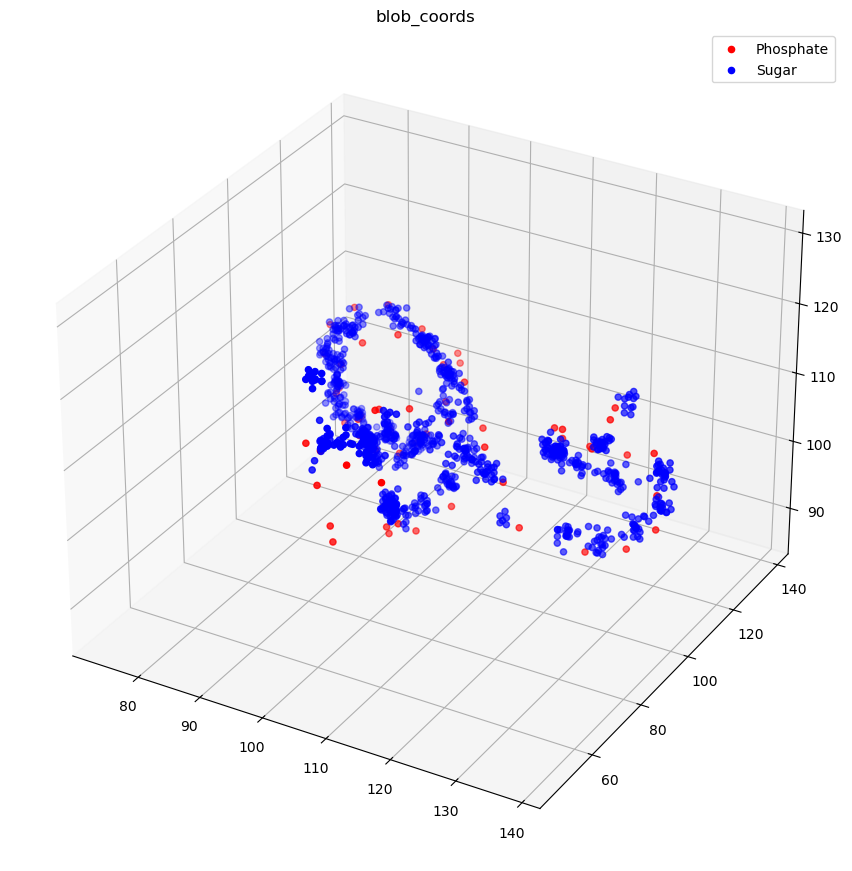

BFS Search COM Merged
Max Dens: 179.37269592285156 and Min Dens: 3.053717613220215
Merging Coordinates...


100%|██████████| 59/59 [00:00<00:00, 7178.28it/s]


Checking for relevant parent child relationships...


100%|██████████| 59/59 [00:00<?, ?it/s]


Preparing Final Coordinates...


100%|██████████| 59/59 [00:00<00:00, 7385.22it/s]


... (3 outputs left out)

100%|██████████| 1029/1029 [00:00<00:00, 128561.52it/s]


Preparing Final Coordinates...


100%|██████████| 1029/1029 [00:00<?, ?it/s]


Estimated Bandwidth: 59.92503804927384


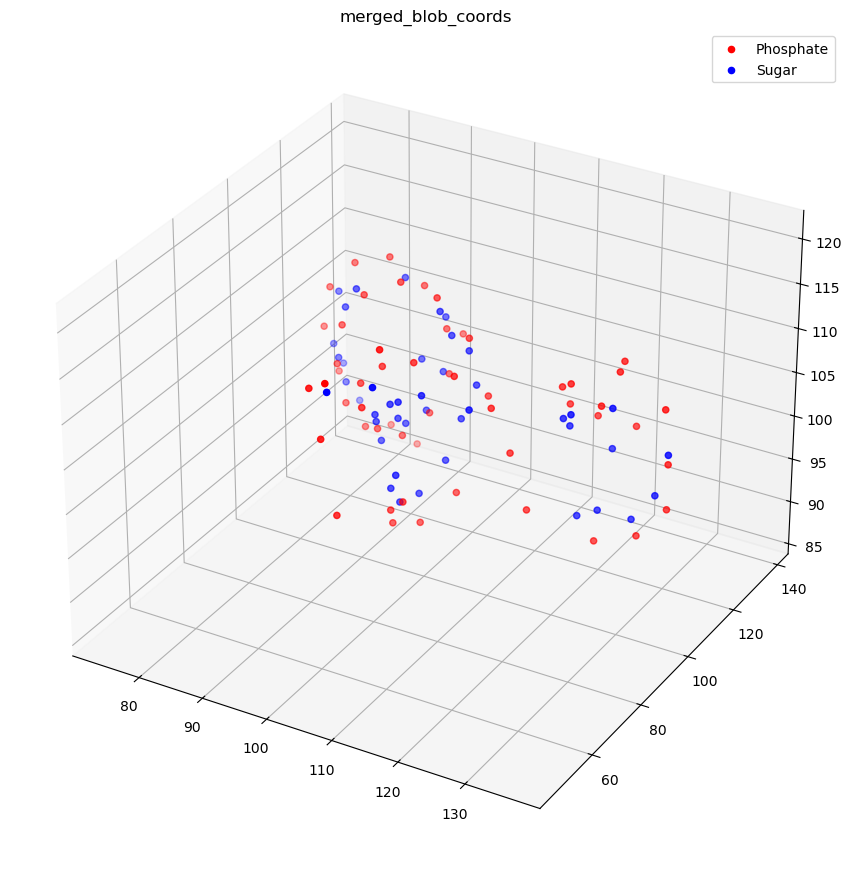

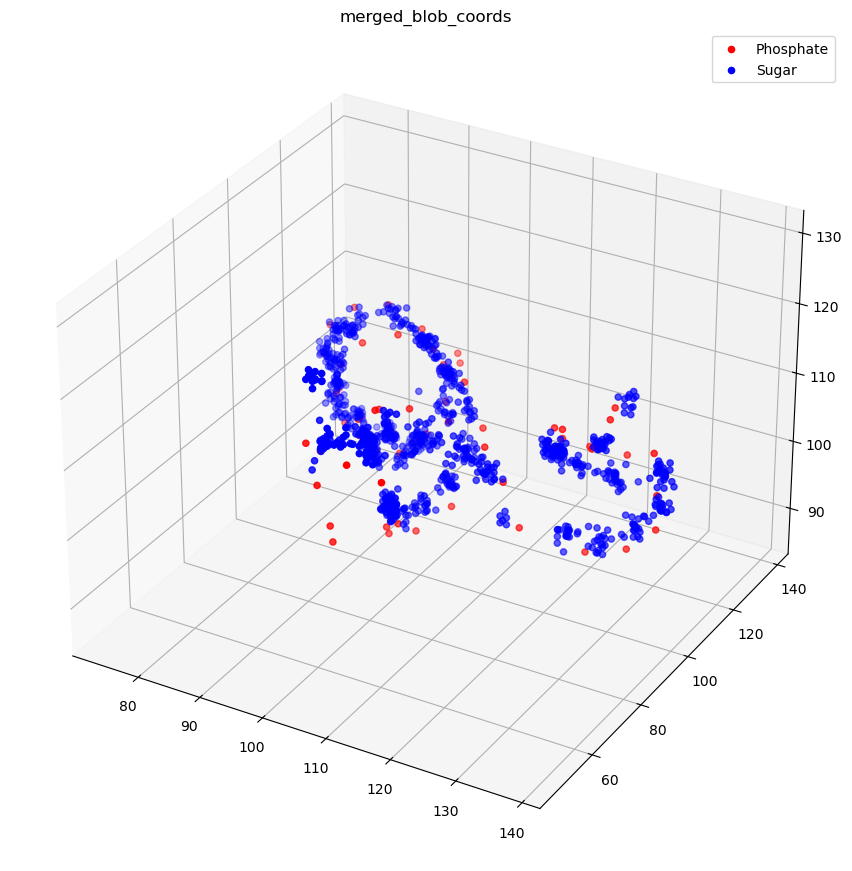

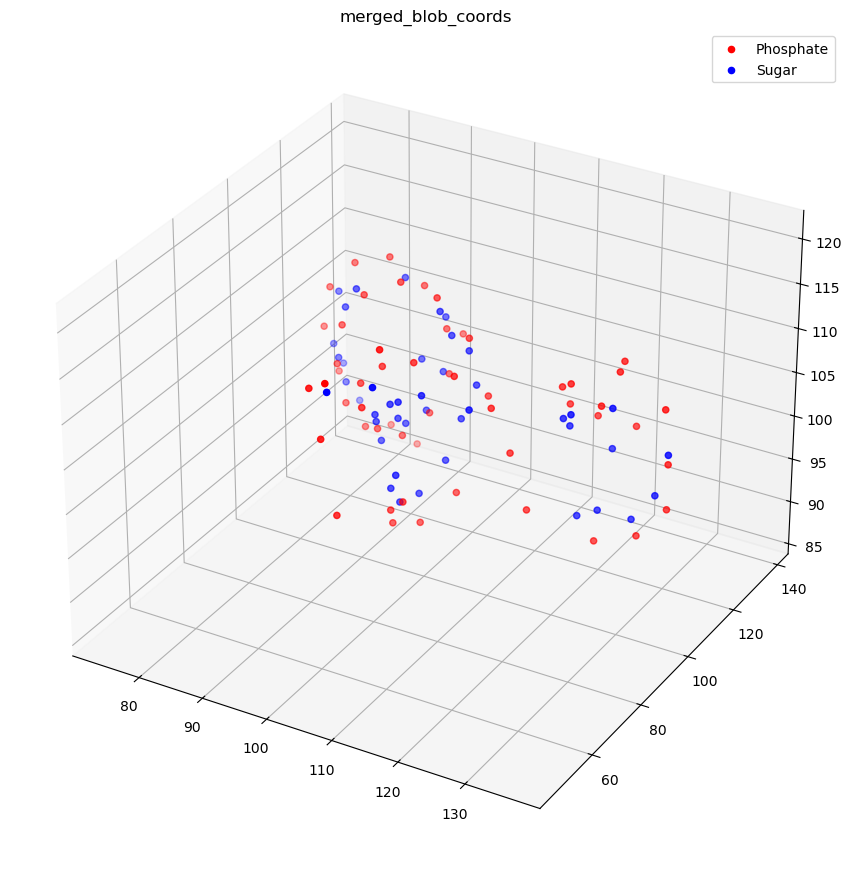

In [3]:
DIRECTORY = r'C:\Users\micha\OneDrive\Desktop\QIBO\CRYOEM_Data\emd_0065'
NORMALIZED_MRC = os.path.join(DIRECTORY,'emd_0065_normalized.mrc')
PHOSPHATE_KEY_ATOMS = os.path.join(DIRECTORY, 'emd_0065.map_key_atoms_2_possibility.mrc')
SUGAR_KEY_ATOMS = os.path.join(DIRECTORY, 'emd_0065.map_key_atoms_3_possibility.mrc')
SECONDARY_STRUCTURE = os.path.join(DIRECTORY,'emd_0065.map_secondary_strctures_4_possibility.mrc')


main(DIRECTORY, NORMALIZED_MRC, PHOSPHATE_KEY_ATOMS, SECONDARY_STRUCTURE, SUGAR_KEY_ATOMS)


=== MRC File Read ===
EM_map Shape: (338, 338, 338)
Cell Dimensions (angstroms): (337.5, 337.5, 337.5)
Array Dimensions: (338, 338, 338)
Orientation (MAPC, MAPR, MAPS): [1, 2, 3]
Origin: [0, 0, 0]
Key Atoms: Phosphates
Secondary Structure, Initializing
Key Atoms: Sugar
Secondary Structure Considered
Method:PHOSPHATE_SS
There were 73 points found, above the threshold!
the threshold was {keyAtom_threshold} and the density threshold was {b_bone_threshold}!
Secondary Structure Considered w/ Sugar UNet
Method:SUGAR_SS
There were 198 points found, above the threshold!
the threshold was {keyAtom_threshold} and the density threshold was {b_bone_threshold}!
[[109 154 196]
 [109 154 197]
 [109 155 196]
 [109 155 197]
 [110 154 195]
 [110 154 196]
 [110 154 197]
 [110 155 195]
 [110 155 196]
 [110 155 197]
 [110 156 196]
 [110 156 197]
 [111 150 200]
 [111 150 201]
 [111 150 202]
 [111 151 200]
 [111 151 201]
 [111 154 196]
 [111 154 197]
 [111 155 195]
 [111 155 196]
 [111 155 197]
 [111 156 196

BFS: 100%|██████████| 73/73 [00:00<00:00, 8913.66it/s]

Size of Blob 4
Number of New Blob Starts 1


[[108 155 198]
 [108 155 199]
 [108 156 198]
 [108 156 199]
 [108 157 198]
 [108 157 199]
 [109 155 198]
 [109 155 199]
 [109 156 197]
 [109 156 198]
 [109 156 199]
 [109 157 198]
 [109 157 199]
 [109 158 198]
 [109 158 199]
 [110 152 201]
 [110 152 202]
 [110 152 203]
 [110 152 204]
 [110 153 201]
 [110 153 202]
 [110 153 203]
 [110 153 204]
 [110 154 201]
 [110 154 202]
 [110 154 203]
 [110 155 198]
 [110 156 198]
 [110 156 199]
 [110 157 197]
 [110 157 198]
 [110 157 199]
 [111 151 203]
 [111 152 201]
 [111 152 202]
 [111 152 203]
 [111 152 204]
 [111 153 201]
 [111 153 202]
 [111 153 203]
 [111 153 204]
 [111 154 201]
 [111 154 202]
 [111 154 203]
 [112 149 203]
 [112 149 204]
 [112 149 205]
 [112 150 204]
 [112 150 205]
 [112 151 204]
 [112 151 205]
 [112 152 201]
 [112 152 202]
 [112 152 203]
 [112 152 204]
 [112 153 201]
 [112 153 202]
 [112 153 203]
 [112 153 204]
 [113 148 203]
 [113 148 204]
 [113 149 202]
 [113 149 203]
 [113 149 204]
 [113 149 205]
 [113 149 206]
 [113 150 

BFS: 100%|██████████| 198/198 [00:00<00:00, 25416.13it/s]

Size of Blob 106
Number of New Blob Starts 1
BFS Search COM


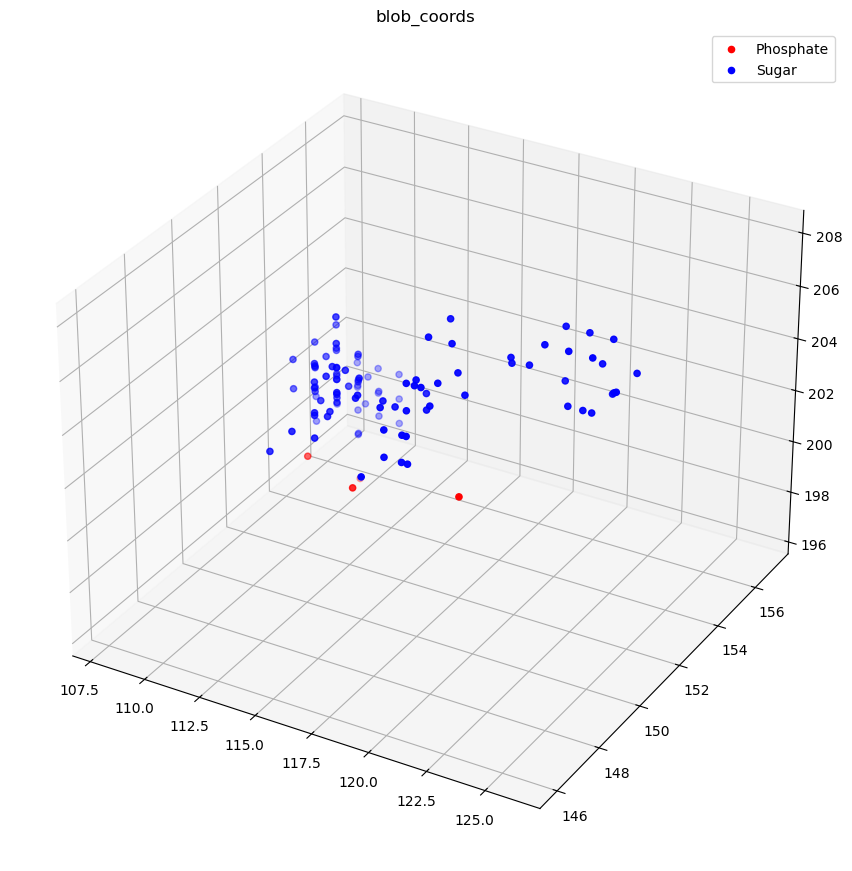

BFS Search COM Merged
Max Dens: 142.07525634765625 and Min Dens: 124.84972381591797
Merging Coordinates...


100%|██████████| 4/4 [00:00<?, ?it/s]


Checking for relevant parent child relationships...


100%|██████████| 4/4 [00:00<?, ?it/s]


Preparing Final Coordinates...


100%|██████████| 4/4 [00:00<?, ?it/s]


... (3 outputs left out)

100%|██████████| 106/106 [00:00<?, ?it/s]


Preparing Final Coordinates...


100%|██████████| 106/106 [00:00<?, ?it/s]

Estimated Bandwidth: 7.561495605486903


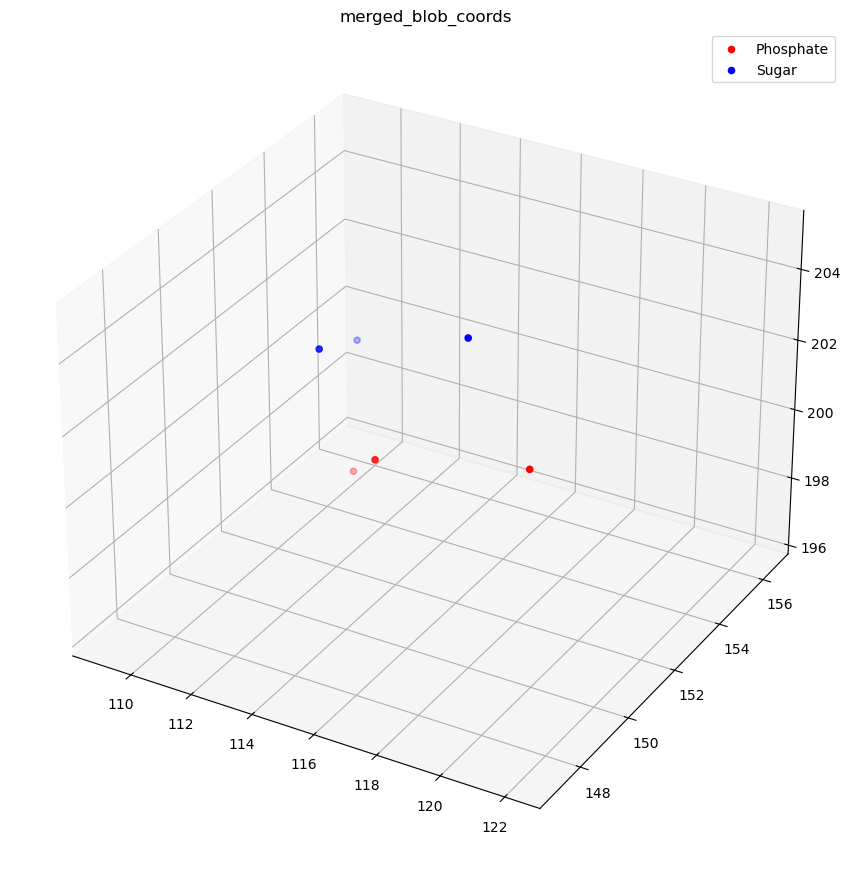

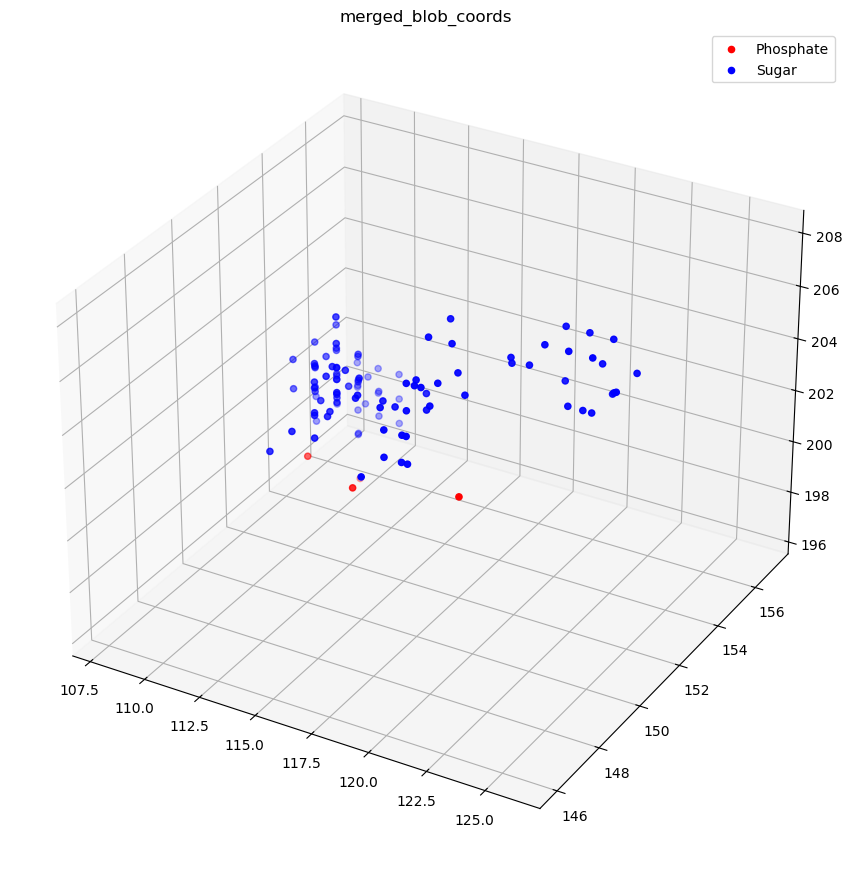

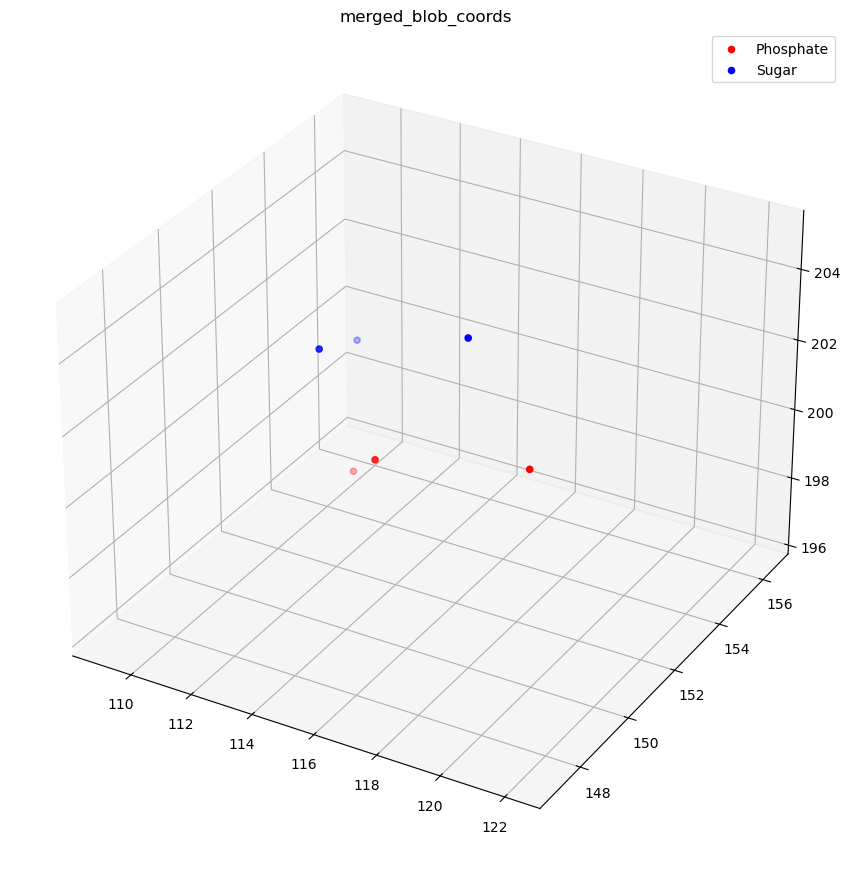

In [4]:
DIRECTORY = r'C:\Users\micha\OneDrive\Desktop\QIBO\CRYOEM_Data\emd_0128'
NORMALIZED_MRC = os.path.join(DIRECTORY,'emd_0128_normalized.mrc')
PHOSPHATE_KEY_ATOMS = os.path.join(DIRECTORY, 'emd_0128.map_key_atoms_2_possibility.mrc')
SUGAR_KEY_ATOMS = os.path.join(DIRECTORY, 'emd_0128.map_key_atoms_3_possibility.mrc')
SECONDARY_STRUCTURE = os.path.join(DIRECTORY,'emd_0128.map_secondary_strctures_4_possibility.mrc')


main(DIRECTORY, NORMALIZED_MRC, PHOSPHATE_KEY_ATOMS, SECONDARY_STRUCTURE, SUGAR_KEY_ATOMS)


=== MRC File Read ===
EM_map Shape: (445, 445, 445)
Cell Dimensions (angstroms): (445.1999816894531, 445.1999816894531, 445.1999816894531)
Array Dimensions: (445, 445, 445)
Orientation (MAPC, MAPR, MAPS): [1, 2, 3]
Origin: [0, 0, 0]
Key Atoms: Phosphates
Secondary Structure, Initializing
Key Atoms: Sugar
Secondary Structure Considered
Method:PHOSPHATE_SS
There were 82861 points found, above the threshold!
the threshold was {keyAtom_threshold} and the density threshold was {b_bone_threshold}!
Secondary Structure Considered w/ Sugar UNet
Method:SUGAR_SS
There were 266780 points found, above the threshold!
the threshold was {keyAtom_threshold} and the density threshold was {b_bone_threshold}!
[[114 215 210]
 [115 214 209]
 [115 214 210]
 ...
 [312 236 280]
 [312 237 279]
 [312 237 280]]
Number of Points to Traverse 82861
Visited (445, 445, 445)


BFS: 100%|██████████| 82861/82861 [00:03<00:00, 21220.75it/s]


Size of Blob 4358
Number of New Blob Starts 1
[[115 217 209]
 [115 217 210]
 [115 218 208]
 ...
 [311 233 277]
 [311 233 278]
 [311 233 279]]
Number of Points to Traverse 266780
Visited (445, 445, 445)


BFS: 100%|██████████| 266780/266780 [00:14<00:00, 18166.55it/s]


Size of Blob 85169
Number of New Blob Starts 1
BFS Search COM


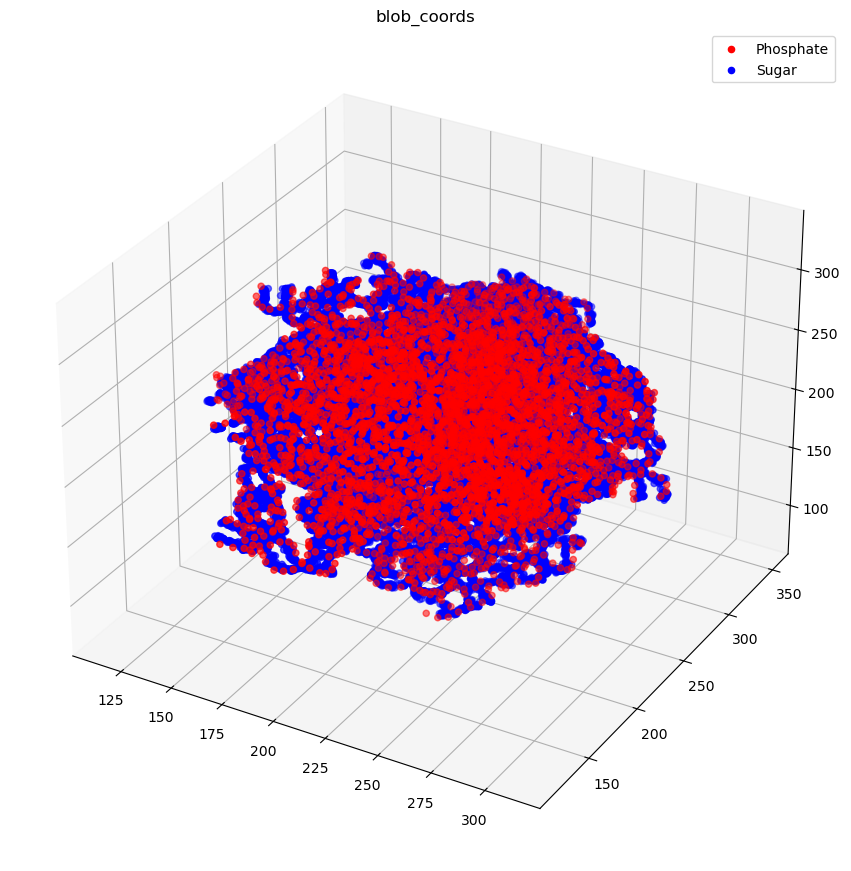

BFS Search COM Merged
Max Dens: 292.55548095703125 and Min Dens: 0.49348264932632446
Merging Coordinates...


100%|██████████| 4354/4354 [00:45<00:00, 96.66it/s] 


Checking for relevant parent child relationships...


100%|██████████| 4354/4354 [00:00<?, ?it/s]


Preparing Final Coordinates...


100%|██████████| 4354/4354 [00:00<00:00, 489440.38it/s]


Max Dens: 198.13475036621094 and Min Dens: 0.0015237079933285713
Merging Coordinates...


  0%|          | 336/84368 [00:37<2:35:35,  9.00it/s]


KeyboardInterrupt: 

In [5]:
DIRECTORY = r'C:\Users\micha\OneDrive\Desktop\QIBO\CRYOEM_Data\emd_3941'
NORMALIZED_MRC = os.path.join(DIRECTORY,'emd_3941_normalized.mrc')
PHOSPHATE_KEY_ATOMS = os.path.join(DIRECTORY, 'emd_3941.map_key_atoms_2_possibility.mrc')
SUGAR_KEY_ATOMS = os.path.join(DIRECTORY, 'emd_3941.map_key_atoms_3_possibility.mrc')
SECONDARY_STRUCTURE = os.path.join(DIRECTORY,'emd_3941.map_secondary_strctures_4_possibility.mrc')


main(DIRECTORY, NORMALIZED_MRC, PHOSPHATE_KEY_ATOMS, SECONDARY_STRUCTURE, SUGAR_KEY_ATOMS)


In [ ]:


import numpy as np
from MEAN_SHIFT_MERGE import mean_shift_clustering, calculate_weighted_center_of_mass

OUTPUT_DIR = r"C:\Users\micha\OneDrive\Desktop\QIBO\CRYOEM_Data\emd_3941\clustering_output"
OUTPUT_DIR_NEW = r"C:\Users\micha\OneDrive\Desktop\QIBO\CRYOEM_Data\emd_3941\clustering_output2"

phos_merge_data = np.loadtxt(os.path.join(OUTPUT_DIR,'phosphate_merged_blob_coords.xyz'), dtype=float, skiprows=2, usecols=range(1, 4))
sugar_merge_data = np.loadtxt(os.path.join(OUTPUT_DIR,'sugar_merged_blob_coords.xyz'), dtype=float, skiprows=2, usecols=range(1, 4))

print(sugar_merge_data.shape)

# Estimate bandwidth
bandwidth = estimate_bandwidth(phos_merge_data, quantile=.90)
bandwidth_sugar = estimate_bandwidth(sugar_merge_data, quantile=.5)

print("Estimated Bandwidth:", bandwidth)

data_pho, masses_pho, labels_pho, cluster_centers_original_pho = mean_shift_clustering(phos_merge_data, [], 1/bandwidth)
data_sugar, masses_sugar, labels_sugar, cluster_centers_original_sugar = mean_shift_clustering(sugar_merge_data, [], 1/bandwidth_sugar)

print(len(np.unique(labels_pho)))
print(len(np.unique(labels_sugar)))

#Switch the first and second columns of the data
cluster_centers_original_pho = cluster_centers_original_pho[:, [2, 1, 0]]
cluster_centers_original_sugar = cluster_centers_original_sugar[:, [2, 1, 0]]

COORDINATE_UTILS.plot_in_3D(phos_merge_data, sugar_merge_data,'merged_blob_coords')
COORDINATE_UTILS.plot_in_3D(cluster_centers_original_pho, cluster_centers_original_sugar,'merged_blob_coords')
COORDINATE_UTILS.write_as_xyz(cluster_centers_original_pho, OUTPUT_DIR_NEW, 'phosphate_merged_blob_coords')
COORDINATE_UTILS.write_as_xyz(cluster_centers_original_sugar, OUTPUT_DIR_NEW, 'sugar_merged_blob_coords')
